# Recovering ring-2 stimulus angle from the ring-1 region

In the `patched_wiring` network from notebook 02 (50×50 torus, d = 10, seed 0), each input group reaches only its own patch. Ring 2's sixteen inputs never touch the ring-1 patch. **Can the ring-2 stimulus angle still be read out linearly from the ring-1 patch, and when?**

Whatever reaches ring 1 must travel through recurrence. The two ring patches are about 11 units apart, edge to edge, so at d = 10 the information takes at least 2 recurrent steps (200 ms).

**Trials.** The 42 single-bump tasks: the go/anti family and the match family (dms/dnms/dmc/dnmc), including their int and seq variants. Each puts its one stimulus on ring 1 or ring 2 at random. Each task runs 128 trials as one stream, the way training and evaluation do. The decoded variable is the first stimulus's true angle, taken from the trial record. In match tasks, that is the sample, so the later steps test whether it survives the delay.

**Decoder.** At each step τ relative to stimulus onset, a ridge regression from a region's unit activity to (cos θ, sin θ) is fit and scored on held-out trials. It uses 5-fold cross-validation stratified by task, with per-unit z-scoring and ridge strength fit on training folds only. The score is the fraction of held-out trials decoded within ±22.5° (one ring unit), where chance is 0.125. The null is 20 refits with shuffled angles, and we show its 95th percentile.

**Regions.**

| region | trials | role |
|---|---|---|
| `ring1` | ring 2 | **the question**: the ring-1 patch (324 units) |
| `ring2` | ring 2 | ceiling: the patch that receives the stimulus |
| `ring1_self` | ring 1 | reference: the ring-1 patch decoding its own input |
| `ring1_near` / `matched` | ring 2 | paired control: 160 ring-1 units, each paired with an input-free unit at the same distance from the ring-2 patch (within 0.5) |

Ring 1 is the part of the sheet farthest from ring 2. No unit outside it is more than 17.5 units from the ring-2 patch, while ring-1 units reach 22.6. So the distance-matched control can only pair ring 1's nearer units. Its input-free partners end up in a band just outside ring 1's near edge: a median of 3 units from the patch, well within one recurrent step. They test ring 1 against its *immediate neighbourhood* at the same distance from ring 2, not against a far-away region.

Running this notebook takes about 20 minutes: about 8 for seed 0 with the shuffle null, plus about 1½ minutes for each of the other 8 seeds. The model weights are git-ignored. To regenerate them, run `python -m cortical.train --condition patched_wiring --seed 0` (notebook 02).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.patches import Circle, Rectangle

from cogtasks import make_task
from cogtasks.modcog._envs import _Reach
from cortical.decode import HIT_TOLERANCE, circular_error, collect, decode_over_time, regions
from cortical.model import MaskedRNN
from cortical.wiring import LAYOUT_B_LARGE, input_mask

L, D = 50, 10
MODEL = "../results/02_input_patches/patched_wiring_s0/model.pt"
SURFACE, INK, MUTED, RULE = "#fcfcfb", "#0b0b0b", "#52514e", "#c3c2b7"
COLORS = {  # categorical slots 1-5, validated; every line also carries a text label
    "ring1": "#2a78d6",
    "ring2": "#eb6834",
    "ring1_self": "#1baf7a",
    "ring1_near": "#eda100",
    "matched": "#e87ba4",
}
LABELS = {
    "ring1": "ring-1 patch (ring-2 trials)",
    "ring2": "ring-2 patch (ceiling)",
    "ring1_self": "ring-1 patch, own input (ring-1 trials)",
    "ring1_near": "ring-1 near units (160)",
    "matched": "distance-matched input-free (160)",
}
CHANCE = 1 / 8
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "text.color": INK,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.edgecolor": RULE,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 9,
    }
)

device = "mps" if torch.backends.mps.is_available() else "cpu"
model = MaskedRNN(L, D, input_mask(L, LAYOUT_B_LARGE))
model.load_state_dict(torch.load(MODEL, map_location="cpu"))
model = model.to(device).eval()
units_by_region = regions(L, LAYOUT_B_LARGE)
recorded = np.unique(np.concatenate(list(units_by_region.values())))
trials = collect(model, units=recorded, device=device)
n_ring1, n_ring2 = np.sum(trials.modality == 1), np.sum(trials.modality == 2)
print(f"{len(trials.task)} trials: {n_ring1} ring-1, {n_ring2} ring-2")

5376 trials: 2688 ring-1, 2688 ring-2


## Where the regions sit

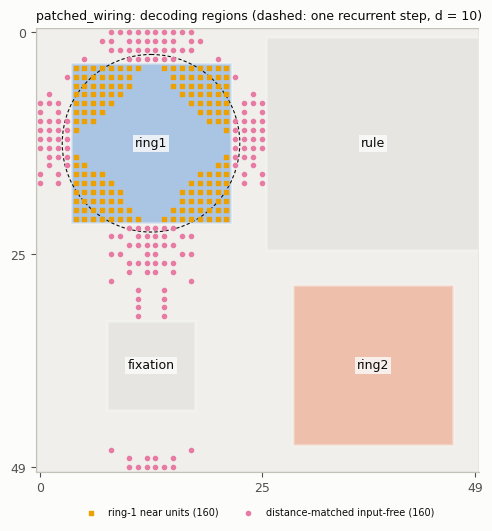

In [2]:
fig, ax = plt.subplots(figsize=(5.2, 5.2), layout="constrained")
ax.set_xlim(-0.5, L - 0.5)
ax.set_ylim(L - 0.5, -0.5)
ax.set_aspect("equal")
ax.add_patch(Rectangle((-0.5, -0.5), L, L, facecolor="#f0efec", edgecolor=RULE))
for group, (centre, size) in LAYOUT_B_LARGE.items():
    x0, y0 = centre[0] - size / 2, centre[1] - size / 2
    color = {"ring1": COLORS["ring1"], "ring2": COLORS["ring2"]}.get(group, "#d6d4cf")
    ax.add_patch(
        Rectangle((x0, y0), size, size, facecolor=color, alpha=0.35, edgecolor=SURFACE, lw=2)
    )
    ax.text(
        *centre,
        group,
        ha="center",
        va="center",
        fontsize=9,
        color=INK,
        bbox={"facecolor": SURFACE, "edgecolor": "none", "alpha": 0.8, "pad": 1.5},
    )
for name, marker in (("ring1_near", "s"), ("matched", "o")):
    y, x = np.divmod(units_by_region[name], L)
    ax.scatter(x, y, s=9, marker=marker, color=COLORS[name], label=LABELS[name], zorder=3)
ax.add_patch(Circle((12.5, 12.5), D, facecolor="none", edgecolor=INK, lw=0.8, ls=(0, (3, 2))))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncols=2, frameon=False, fontsize=7)
ax.set_xticks([0, 25, 49])
ax.set_yticks([0, 25, 49])
ax.set_title(
    "patched_wiring: decoding regions (dashed: one recurrent step, d = 10)", loc="left", fontsize=9
)
plt.show()

## Decoding over time

Each region gets one decoder per step τ, at 100 ms per step. τ = 0 is the first step the stimulus is on the input. The grey band runs from chance up to the shuffle null's 95th percentile (the highest across regions).

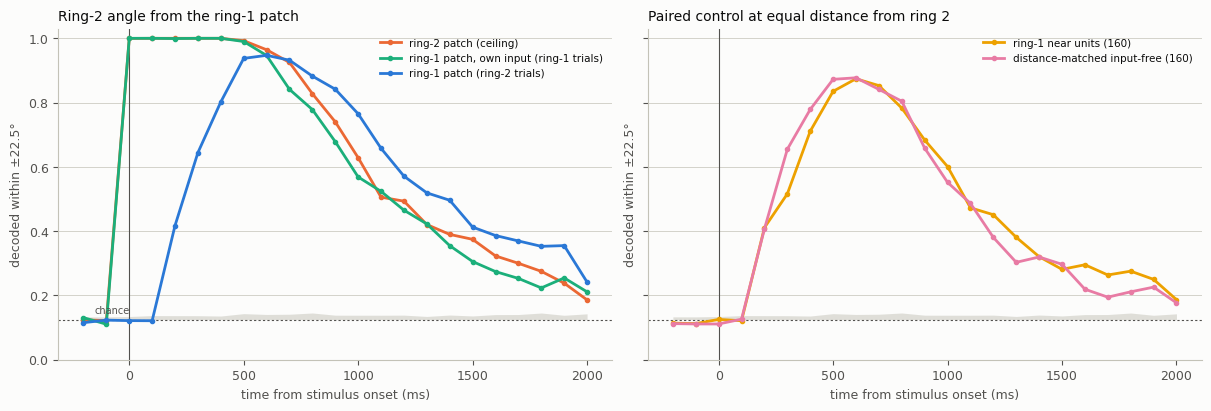

accuracy at τ (ms) =                        0    200    300    500   1000   1500   2000
ring-1 patch (ring-2 trials)             0.12   0.42   0.64   0.94   0.76   0.41   0.24
ring-2 patch (ceiling)                   1.00   1.00   1.00   0.99   0.63   0.37   0.19
ring-1 patch, own input (ring-1 trials)   1.00   1.00   1.00   0.99   0.57   0.31   0.21
ring-1 near units (160)                  0.13   0.41   0.52   0.84   0.60   0.28   0.19
distance-matched input-free (160)        0.11   0.41   0.65   0.87   0.55   0.30   0.18
shuffle null (95th pct, max over regions)   0.13   0.14   0.14   0.14   0.14   0.14   0.14


In [3]:
def run(name):
    on = trials.modality == (1 if name == "ring1_self" else 2)
    cols = np.searchsorted(recorded, units_by_region[name])
    return decode_over_time(
        trials.activity[on][:, :, cols], trials.angle[on], trials.valid[on], trials.task[on], seed=0
    ), on


results = {name: run(name) for name in COLORS}
tau_ms = results["ring1"][0].tau * 100
null = np.max([r.null95 for r, _ in results.values()], axis=0)


def panel(ax, names, title):
    ax.fill_between(tau_ms, CHANCE, null, color=RULE, alpha=0.5, lw=0)
    ax.axhline(CHANCE, color=MUTED, lw=0.8, ls=(0, (2, 2)))
    ax.axvline(0, color=MUTED, lw=0.8)
    for name in names:
        r = results[name][0]
        ax.plot(tau_ms, r.accuracy, color=COLORS[name], lw=2, marker="o", ms=3, label=LABELS[name])
    ax.set_ylim(0, 1.03)
    ax.set_xlabel("time from stimulus onset (ms)")
    ax.set_ylabel("decoded within ±22.5°")
    ax.set_title(title, loc="left", fontsize=10)
    ax.grid(axis="y", color=RULE, lw=0.5)
    ax.legend(loc="upper right", frameon=False, fontsize=7.5)


fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4), layout="constrained", sharey=True)
panel(left, ("ring2", "ring1_self", "ring1"), "Ring-2 angle from the ring-1 patch")
panel(right, ("ring1_near", "matched"), "Paired control at equal distance from ring 2")
left.text(-150, CHANCE + 0.02, "chance", fontsize=7, color=MUTED)
plt.show()

steps = [0, 2, 3, 5, 10, 15, 20]
print(f"{'accuracy at τ (ms) =':38s}" + "".join(f"{s * 100:>7d}" for s in steps))
for name in COLORS:
    r = results[name][0]
    print(f"{LABELS[name]:38s}" + "".join(f"{r.accuracy[r.tau == s][0]:7.2f}" for s in steps))
print(
    f"{'shuffle null (95th pct, max over regions)':38s}"
    + "".join(f"{null[results['ring1'][0].tau == s][0]:7.2f}" for s in steps)
)

## Across seeds

Everything above uses seed 0. Here the main measurement and the paired control are repeated on `patched_wiring` seeds 0–8, which were trained identically. These runs skip the shuffle null (seed 0's null above stays under 0.15 at every step). Each curve shows the mean over seeds with the full range shaded.

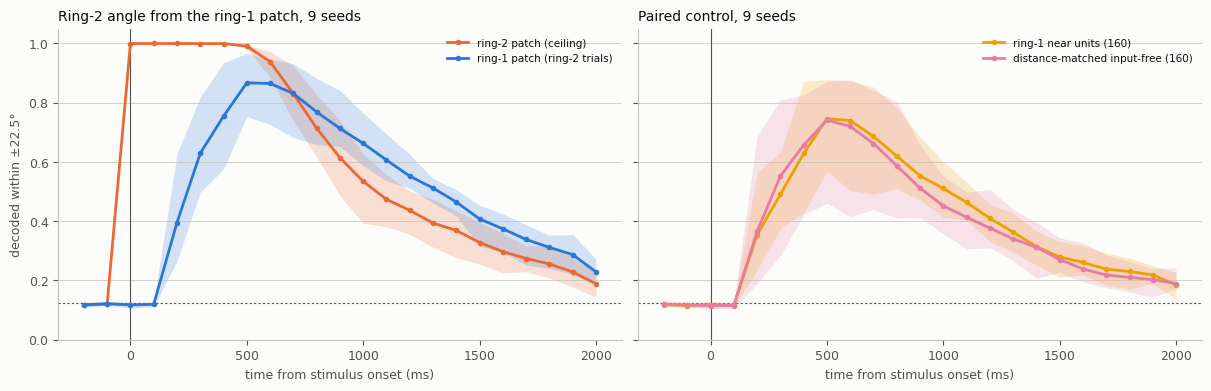

mean over 9 seeds [min, max] at ms =                     0               100               200               300               500              1000
ring-1 patch (ring-2 trials)              0.12 [0.11,0.13]  0.12 [0.11,0.13]  0.40 [0.27,0.63]  0.63 [0.50,0.82]  0.87 [0.75,0.97]  0.66 [0.59,0.76]
ring-2 patch (ceiling)                    1.00 [1.00,1.00]  1.00 [1.00,1.00]  1.00 [1.00,1.00]  1.00 [1.00,1.00]  0.99 [0.98,1.00]  0.53 [0.39,0.63]
ring-1 near units (160)                   0.12 [0.11,0.13]  0.12 [0.11,0.12]  0.35 [0.23,0.57]  0.49 [0.38,0.63]  0.75 [0.57,0.88]  0.51 [0.41,0.60]
distance-matched input-free (160)         0.12 [0.11,0.12]  0.12 [0.11,0.13]  0.37 [0.19,0.69]  0.55 [0.28,0.81]  0.74 [0.46,0.87]  0.45 [0.36,0.55]


In [4]:
SEED_RANGE = range(9)
tau = results["ring1"][0].tau


def seed_curves(seed):
    net = MaskedRNN(L, D, input_mask(L, LAYOUT_B_LARGE))
    path = f"../results/02_input_patches/patched_wiring_s{seed}/model.pt"
    net.load_state_dict(torch.load(path, map_location="cpu"))
    net = net.to(device).eval()
    seed_trials = collect(net, units=recorded, device=device)
    on = seed_trials.modality == 2
    curves = {}
    for name in ("ring1", "ring2", "ring1_near", "matched"):
        cols = np.searchsorted(recorded, units_by_region[name])
        r = decode_over_time(
            seed_trials.activity[on][:, :, cols],
            seed_trials.angle[on],
            seed_trials.valid[on],
            seed_trials.task[on],
            n_shuffles=0,
            seed=0,
        )
        curves[name] = r.accuracy
    return curves


by_seed = {s: seed_curves(s) for s in SEED_RANGE}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained", sharey=True)
for ax, names, title in (
    (axes[0], ("ring2", "ring1"), "Ring-2 angle from the ring-1 patch, 9 seeds"),
    (axes[1], ("ring1_near", "matched"), "Paired control, 9 seeds"),
):
    ax.axhline(CHANCE, color=MUTED, lw=0.8, ls=(0, (2, 2)))
    ax.axvline(0, color=MUTED, lw=0.8)
    for name in names:
        stack = np.array([by_seed[s][name] for s in SEED_RANGE])
        ax.fill_between(tau * 100, stack.min(0), stack.max(0), color=COLORS[name], alpha=0.2, lw=0)
        ax.plot(
            tau * 100, stack.mean(0), color=COLORS[name], lw=2, marker="o", ms=3, label=LABELS[name]
        )
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("time from stimulus onset (ms)")
    ax.set_title(title, loc="left", fontsize=10)
    ax.grid(axis="y", color=RULE, lw=0.5)
    ax.legend(loc="upper right", frameon=False, fontsize=7.5)
axes[0].set_ylabel("decoded within ±22.5°")
plt.show()

shown = [0, 1, 2, 3, 5, 10]
print(f"{'mean over 9 seeds [min, max] at ms =':40s}" + "".join(f"{s * 100:>18d}" for s in shown))
for name in ("ring1", "ring2", "ring1_near", "matched"):
    stack = np.array([by_seed[s][name] for s in SEED_RANGE])
    cells = [
        f"{stack[:, i].mean():.2f} [{stack[:, i].min():.2f},{stack[:, i].max():.2f}]"
        for i in (np.flatnonzero(tau == s)[0] for s in shown)
    ]
    print(f"{LABELS[name]:40s}" + "".join(f"{c:>18s}" for c in cells))

## Late steps: what else is happening in the trial

After the stimulus ends, two events can change what the patches carry, so the late steps are split by them. These are the same pooled decoders, with ring 1 and ring 2 scored on the identical trials.

- **Match tasks:** a test stimulus follows the sample, landing on the *same* ring, so for ring-2 trials it lands in the ring-2 patch. On non-match trials it sits at a different angle. The test starts 500–1600 ms after sample onset (median 1000 ms). The 12 base and seq match tasks fix their delay once per task instance, and the 8 int variants draw it per trial from 0–1100 ms.
- **Go/anti tasks:** the response period starts 1000 ms after onset for most tasks (immediately for the reaction-time tasks, and at a variable time for the int tasks). The readout's response depends on the stimulus angle, so the angle stays decodable while the network responds.

Points with fewer than 30 trials are left out.

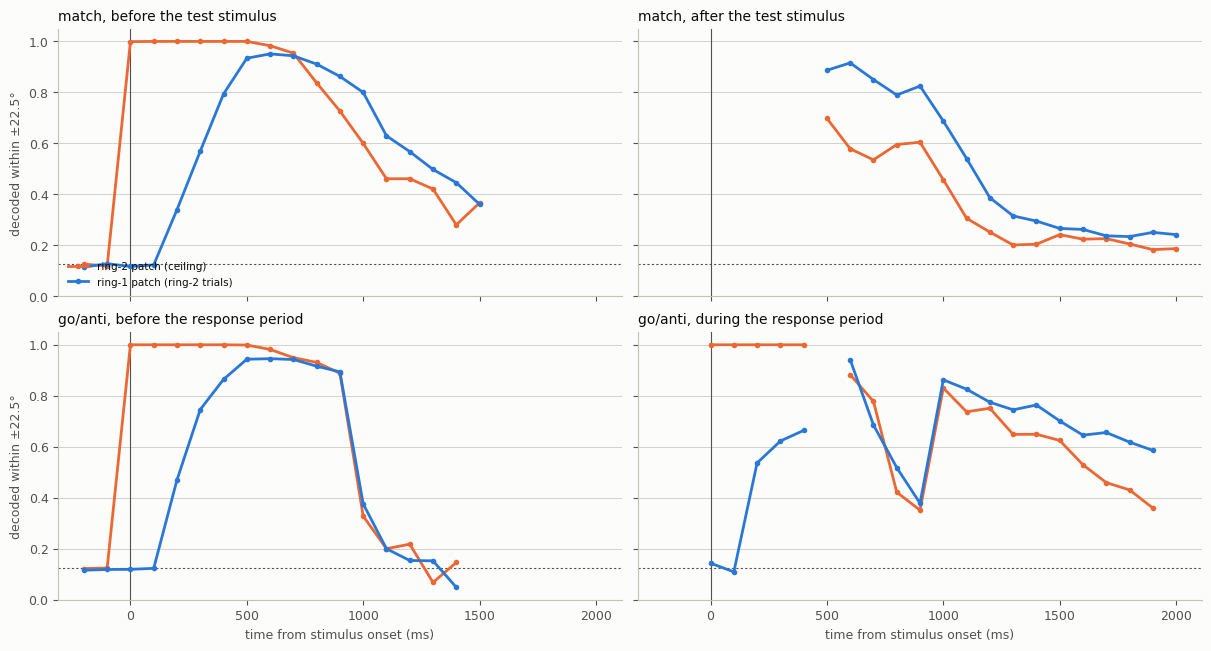

                                                500    600    800   1000   1200   1300   1500   ms
match, before the test stimulus                0.93   0.95   0.91   0.80   0.57   0.50   0.36   ring 1
                                               1.00   0.98   0.84   0.60   0.46   0.42   0.37   ring 2
                                               1227   1185    966    550    479    456    169   trials
match, after the test stimulus                 0.89   0.92   0.79   0.69   0.39   0.32   0.27   ring 1
                                               0.70   0.58   0.60   0.46   0.25   0.20   0.24   ring 2
                                                 53     95    314    730    801    824   1111   trials
go/anti, before the response period            0.94   0.95   0.92   0.38   0.15   0.15    nan   ring 1
                                               1.00   0.98   0.93   0.33   0.22   0.07    nan   ring 2
                                               1005    990    941    125     

In [5]:
def task_family(task):
    return "go/anti" if isinstance(make_task("modcog", task).unwrapped, _Reach) else "match"


family = np.array([task_family(t) for t in trials.task])
tau = results["ring1"][0].tau
MIN_TRIALS = 30


def split_accuracy(name, step_mask):
    """Accuracy per tau over (trial, tau) cells where step_mask holds; NaN below MIN_TRIALS."""
    r, on = results[name]
    pred, truth = r.predicted, trials.angle[on][:, None]
    cells = step_mask & ~np.isnan(pred)
    hits = (circular_error(np.nan_to_num(pred), truth) <= HIT_TOLERANCE) & cells
    n = cells.sum(0)
    return np.where(n >= MIN_TRIALS, hits.sum(0) / np.maximum(n, 1), np.nan), n


on2 = trials.modality == 2
fam2, test_tau, decision_tau = (
    family[on2],
    trials.test_tau[on2][:, None],
    trials.decision_tau[on2][:, None],
)
splits = {
    "match, before the test stimulus": (fam2 == "match")[:, None] & (tau < test_tau),
    "match, after the test stimulus": (fam2 == "match")[:, None] & (tau >= test_tau),
    "go/anti, before the response period": (fam2 == "go/anti")[:, None] & (tau < decision_tau),
    "go/anti, during the response period": (fam2 == "go/anti")[:, None] & (tau >= decision_tau),
}
fig, axes = plt.subplots(2, 2, figsize=(12, 6.4), layout="constrained", sharex=True, sharey=True)
for ax, (title, mask) in zip(axes.flat, splits.items(), strict=True):
    ax.axhline(CHANCE, color=MUTED, lw=0.8, ls=(0, (2, 2)))
    ax.axvline(0, color=MUTED, lw=0.8)
    for name in ("ring2", "ring1"):
        acc, _ = split_accuracy(name, mask)
        ax.plot(tau * 100, acc, color=COLORS[name], lw=2, marker="o", ms=3, label=LABELS[name])
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", color=RULE, lw=0.5)
for ax in axes[1]:
    ax.set_xlabel("time from stimulus onset (ms)")
for ax in axes[:, 0]:
    ax.set_ylabel("decoded within ±22.5°")
axes[0, 0].legend(loc="lower left", frameon=False, fontsize=7.5)
plt.show()

shown = [5, 6, 8, 10, 12, 13, 15]
print(f"{'':44s}" + "".join(f"{s * 100:>7d}" for s in shown) + "   ms")
for title, mask in splits.items():
    a1, n = split_accuracy("ring1", mask)
    a2, _ = split_accuracy("ring2", mask)
    idx = [int(np.flatnonzero(tau == s)[0]) for s in shown]
    print(f"{title:44s}" + "".join(f"{a1[i]:7.2f}" for i in idx) + "   ring 1")
    print(f"{'':44s}" + "".join(f"{a2[i]:7.2f}" for i in idx) + "   ring 2")
    print(f"{'':44s}" + "".join(f"{n[i]:7d}" for i in idx) + "   trials")

## Which trials lose the angle, and how

Two follow-up splits on the trials before the response or test:

- **Go/anti:** the standard delay tasks (`dlygo`, `dlyanti` and their `seq` variants, delay 500 ms) against the `int` variants (delays of 0–1100 ms that vary by trial). After about 1 s, only `int` trials are still before their response.
- **Match:** exact-angle tasks (`dms`, `dnms`) against category tasks (`dmc`, `dnmc`, which only need to know which half of the ring the sample was in). Each is scored two ways: the exact angle within ±22.5°, and the right half of the ring (chance 0.5), read off the same decoder's predicted angle.

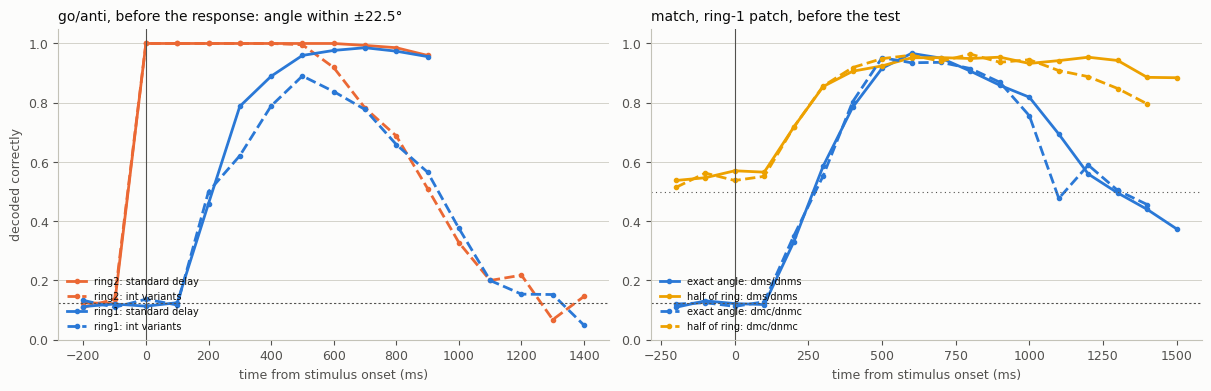

In [6]:
is_int = np.array(["int" in t for t in trials.task])[on2][:, None]
exact = np.array([t.startswith(("dms", "dnms")) for t in trials.task])[on2][:, None]
category = np.array([t.startswith(("dmc", "dnmc")) for t in trials.task])[on2][:, None]
before_response = (fam2 == "go/anti")[:, None] & (tau < decision_tau)
before_test = (fam2 == "match")[:, None] & (tau < test_tau)


def half_ring_accuracy(name, step_mask):
    """Fraction of cells whose decoded angle lies on the same half of the ring (0..π vs π..2π)."""
    r, on = results[name]
    pred, truth = r.predicted, trials.angle[on][:, None]
    cells = step_mask & ~np.isnan(pred)
    same = (np.nan_to_num(pred) > np.pi) == (truth > np.pi)
    n = cells.sum(0)
    return np.where(n >= MIN_TRIALS, (same & cells).sum(0) / np.maximum(n, 1), np.nan), n


fig, (go_ax, match_ax) = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for name in ("ring2", "ring1"):
    for subset, style, tag in ((~is_int, "-", "standard delay"), (is_int, "--", "int variants")):
        acc, _ = split_accuracy(name, before_response & subset)
        go_ax.plot(
            tau * 100,
            acc,
            color=COLORS[name],
            ls=style,
            lw=2,
            marker="o",
            ms=3,
            label=f"{name}: {tag}",
        )
go_ax.set_title("go/anti, before the response: angle within ±22.5°", loc="left", fontsize=10)
go_ax.axhline(CHANCE, color=MUTED, lw=0.8, ls=(0, (2, 2)))
for subset, style, tag in ((exact, "-", "dms/dnms"), (category, "--", "dmc/dnmc")):
    acc, _ = split_accuracy("ring1", before_test & subset)
    half, _ = half_ring_accuracy("ring1", before_test & subset)
    match_ax.plot(
        tau * 100,
        acc,
        color=COLORS["ring1"],
        ls=style,
        lw=2,
        marker="o",
        ms=3,
        label=f"exact angle: {tag}",
    )
    match_ax.plot(
        tau * 100,
        half,
        color=COLORS["ring1_near"],
        ls=style,
        lw=2,
        marker="o",
        ms=3,
        label=f"half of ring: {tag}",
    )
match_ax.set_title("match, ring-1 patch, before the test", loc="left", fontsize=10)
match_ax.axhline(0.5, color=MUTED, lw=0.8, ls=(0, (1, 3)))
match_ax.axhline(CHANCE, color=MUTED, lw=0.8, ls=(0, (2, 2)))
for ax in (go_ax, match_ax):
    ax.axvline(0, color=MUTED, lw=0.8)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("time from stimulus onset (ms)")
    ax.grid(axis="y", color=RULE, lw=0.5)
    ax.legend(loc="lower left", frameon=False, fontsize=7)
go_ax.set_ylabel("decoded correctly")
plt.show()

## What we see

The detailed numbers are for seed 0; the across-seeds section checks the main ones on seeds 0–8.

- **Yes: the ring-2 angle reaches the ring-1 patch, starting 200 ms after onset.** At τ = 0 and 100 ms, decoding from the ring-1 patch sits at chance (0.12). It rises to 0.42 at 200 ms and 0.64 at 300 ms, and peaks at 0.94–0.95 at 500–600 ms. The two-step lag is what the geometry predicts: the patches are about 11 units apart, and recurrence covers at most 10 per step. **The lag is the same in all 9 seeds:** decoding is at chance at 0 and 100 ms and first rises above 0.2 at exactly 200 ms, with a mean of 0.40 (range 0.27–0.63). The ring-2 patch decodes its own stimulus perfectly from the first step, and so does the ring-1 patch for ring-1 stimuli.
- **Once there, it is nearly as good as at the source.** In seed 0, the ring-1 patch matches the ring-2 patch by 500–600 ms (0.94–0.95 against 0.96–0.99) on the identical trials. Across the 9 seeds it peaks somewhat lower: 0.87 on average at 500 ms (range 0.75–0.97), against 0.99 for ring 2.
- **Ring 1 is not special; distance is what matters.** Ring-1 units and input-free units at the same distance from ring 2 carry about the same information: 0.41 against 0.41 at 200 ms, and 0.84 against 0.87 at 500 ms, with 160 units each. Across seeds the two are equal on average (a difference of −0.003 over 200–800 ms), though single seeds differ by up to ±0.17 either way, with ring 1 ahead in 4 of 9. Those input-free units sit just outside ring 1's near edge, so the comparison is with ring 1's immediate neighbourhood. The full ring-1 patch decodes better than its 160 nearer units (0.94 against 0.84 at 500 ms), probably because a larger population gives the decoder more units to average over.
- **Through the delay of match tasks, ring 1 holds the sample somewhat better than ring 2.** Before any test stimulus has appeared, the two match at 600 ms (0.95 against 0.98). By 1 s the ring-1 patch leads, 0.80 against 0.60 (550 trials), and it stays ahead until the trials run out (0.50 against 0.42 at 1.3 s). The larger gap after the test stimulus (for example 0.69 against 0.46 at 1 s) mostly reflects the test landing in the ring-2 patch, which then carries the *test* angle; it is not ring 1 remembering better.
- **Go/anti: the angle is held right up to the response, except in the tasks the network fails.** In the standard delay tasks, both patches decode the angle at 0.96–0.99 through the whole 500 ms delay until the response starts. Those tasks score 1.00. Only the `int` variants, with their longer, variable delays, lose it before the response: ring 1 goes from 0.84 at 700 ms to 0.38 at 1 s and 0.05 at 1.4 s, and ring 2 does the same. Those are the four tasks the network largely fails (accuracy 0.03–0.25). In `int` tasks the correct response is the stimulus angle shifted by an amount set by the delay, so part of the loss could be the network transforming the angle rather than forgetting it; decoding the *target* angle would tell the two apart. During the response period the angle is decodable again (0.86 against 0.83 at 1 s), because the response itself depends on it.
- **Match: over the delay the precise angle blurs, but its coarse position survives.** Before the test, exact-angle decoding from ring 1 falls from about 0.93 at 500 ms to 0.82 (dms/dnms) and 0.76 (dmc/dnmc) at 1 s, and to about 0.5–0.6 by 1.2 s. Over the same steps, which half of the ring the sample was in stays about 90% recoverable (0.93–0.95 at 1 s). This holds equally for tasks that need the exact angle and for category tasks, so it isn't task-specific compression; it looks like a memory whose angle drifts with time. Coarse information is enough for all four match tasks in Mod-Cog: a dms non-match test sits exactly 180° from the sample. That fits their scores of 0.94–1.00.

In summary: on ring-2 trials, ring-2 information spreads through recurrence into the ring-1 patch within 200–500 ms and is as decodable there as at the source. Ring 1 gets it no better than its neighbours at the same distance. Information is **not** generally lost over time. The angle is held through delays the network handles, and its fine detail drifts while its coarse position persists. It is lost outright only in the `int` tasks the network fails, and where a new stimulus replaces it.


## Caveats

- **One network, one seed.** The arrival time and the paired-control comparison should be checked on more seeds.
- **Linear decoding only.** Information that is present but not linearly readable would be missed.
- **Decodable is not the same as used.** These results show that ring-2 information *reaches* ring 1, not that the network relies on it there. That would take a causal test, such as silencing ring 1 on ring-2 trials.
- **The late steps mix stimuli.** For match tasks, the late steps include the test stimulus, which sits at the sample's angle on match trials and elsewhere on non-match trials. They also include trials of different lengths, so fewer trials enter each late step.